# Visualisation of Contest

### Imports

In [3]:
import os
import pandas as pd
import numpy as np
import scipy.stats as stats
from math import floor
import matplotlib.pyplot as plt
import plotly.express as px 
import seaborn as sns
import sys
sys.path.append("../Jeremy")
from visualization import plot_df_histogram, plot_df_two_class
sys.path.append("../Adrian")

plt.rcParams["figure.figsize"] = (12,6)  


In [4]:
id=515
root="../../../newyorker_caption_contest/data/"

contest_df = pd.read_csv(root+str(id)+".csv")
print(contest_df)

      rank                                            caption      mean  \
0        0         Tell me about your childhood very quickly.  2.000000   
1        1     I think that’s all the time we have for today.  1.904762   
2        2               Looks like our time is up for today.  1.888889   
3        3  I'm afraid I'm still going to have to bill you...  1.888889   
4        4  Let's not forget what happened the last time o...  1.888889   
...    ...                                                ...       ...   
4265  4265  Now that we have Obamacare we can live where w...  1.000000   
4266  4266  In an overreaching effort to fully empathize, ...  1.000000   
4267  4267  Brighto! Brighto! It makes old bodies new. We'...  1.000000   
4268  4268           Don't worry; we're on the E train track.  1.000000   
4269  4269  Is this really the only way I can get my thera...  1.000000   

      precision  votes  not_funny  somewhat_funny  funny  
0      0.141220     27          7       

### Scoring methods

Linkert scale method:

|      Rating    |  Score |
| :-------------:| :----: |
| not funny      |  +1    |
| somewhat_funny |  +2    |
| funny          |  +3    |

The mean is the Arithmetic mean of all the scores for a specific caption $\sum_{i=1}^{n} score_i / n$ where $n$ is the number of votes <br>

The precision is the Standard Error of the Mean (SEM) $\sigma / \sqrt{n}$ where $\sigma$ is the standard deviation of the scores $\sigma^2=\frac{1}{n-1}\sum_{i=1}^{n}(mean-score_i)^2$. <br>
1-n ? n?  <br>



The dataframes are already sorted by the mean so we wont change the oreder <br>



## Visulation of the Votes

In [5]:
# Visualisation of tht votes
'''

x = np.arange(len(contest_df))

plt.figure()
#plt.ylim(0, max(contest_df['not_funny']+contest_df['somewhat_funny']+contest_df['funny'])+10)
plt.yscale("log")
plt.bar(x,contest_df['not_funny'], color='green', label='Not funny votes')
plt.bar(x,contest_df['somewhat_funny'], bottom=contest_df['not_funny'],color='red', label='Somewhat funny votes')
plt.bar(x,contest_df['funny'],bottom=(contest_df['not_funny']+contest_df['somewhat_funny']), color='blue', label='funny votes')
plt.title('Distribution of votes')
plt.xlabel('captions')
plt.ylabel('Number of votes')
plt.tight_layout()
plt.legend()
plt.show()
'''

'\n\nx = np.arange(len(contest_df))\n\nplt.figure()\n#plt.ylim(0, max(contest_df[\'not_funny\']+contest_df[\'somewhat_funny\']+contest_df[\'funny\'])+10)\nplt.yscale("log")\nplt.bar(x,contest_df[\'not_funny\'], color=\'green\', label=\'Not funny votes\')\nplt.bar(x,contest_df[\'somewhat_funny\'], bottom=contest_df[\'not_funny\'],color=\'red\', label=\'Somewhat funny votes\')\nplt.bar(x,contest_df[\'funny\'],bottom=(contest_df[\'not_funny\']+contest_df[\'somewhat_funny\']), color=\'blue\', label=\'funny votes\')\nplt.title(\'Distribution of votes\')\nplt.xlabel(\'captions\')\nplt.ylabel(\'Number of votes\')\nplt.tight_layout()\nplt.legend()\nplt.show()\n'

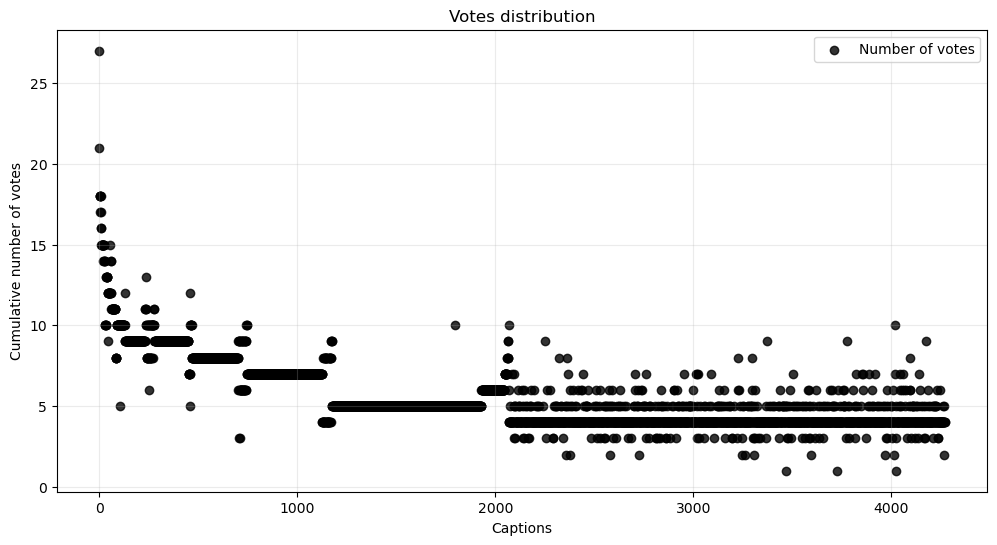

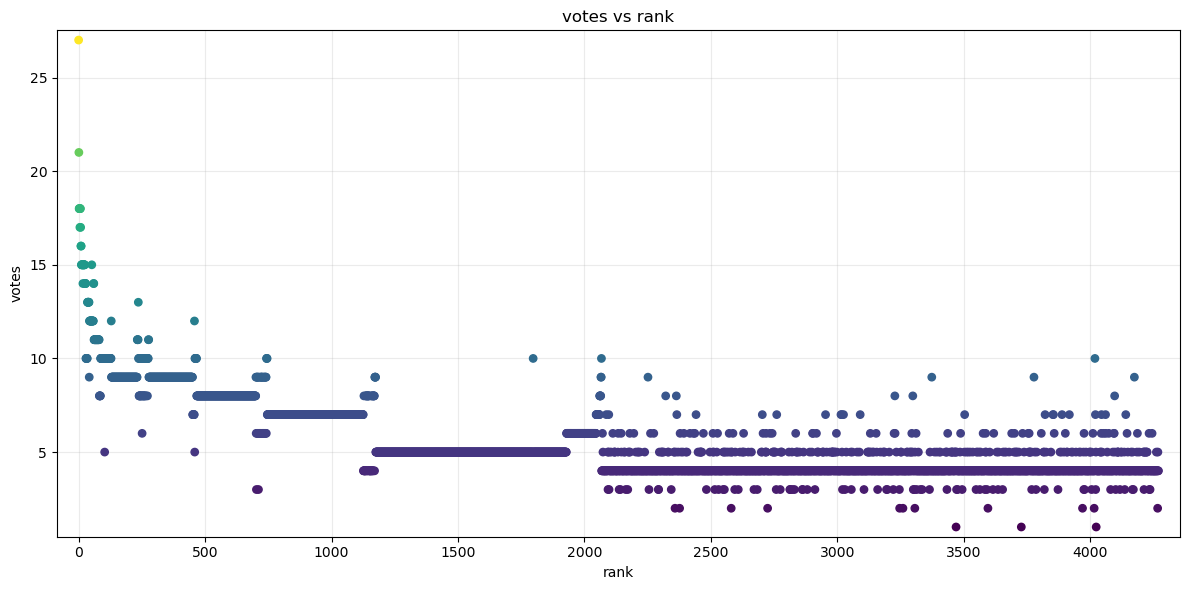

,rank,votes
0,0,27
1,1,21
2,2,18
3,3,18
4,4,18
...,...,...
4265,4265,4
4266,4266,2
4267,4267,5
4268,4268,4


In [6]:
x = np.arange(len(contest_df))

plt.figure(figsize=(12, 6))
if contest_df['votes'].iloc[0]>100:
    plt.yscale("log")
plt.scatter(x, contest_df['votes'], color='black', label='Number of votes', alpha=0.8)
plt.title('Votes distribution')
plt.xlabel('Captions')
plt.ylabel('Cumulative number of votes')
plt.tight_layout
plt.grid(True, alpha=0.25)
plt.legend()


plot_df_two_class(contest_df,'rank','votes',trace=None,figsize=(12,6)) #logscale ? utiliser plusieur couleur sur un graph ?

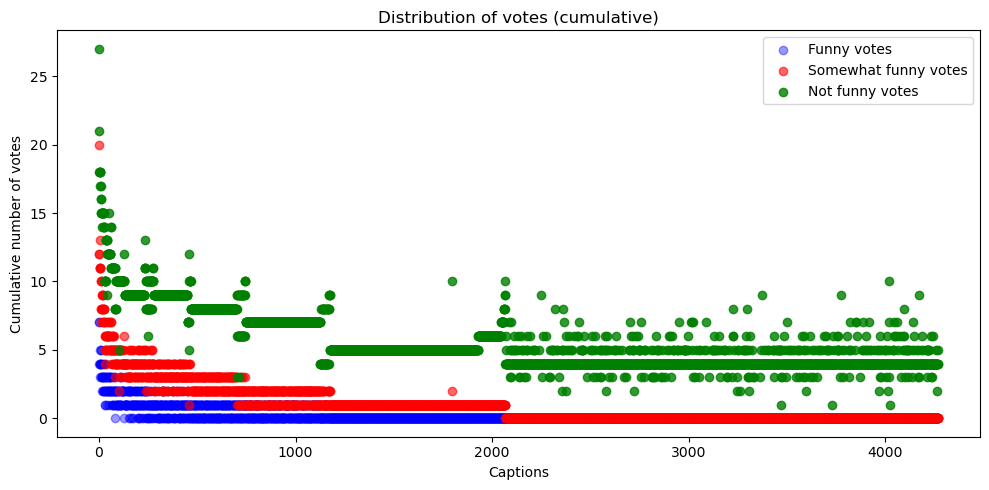

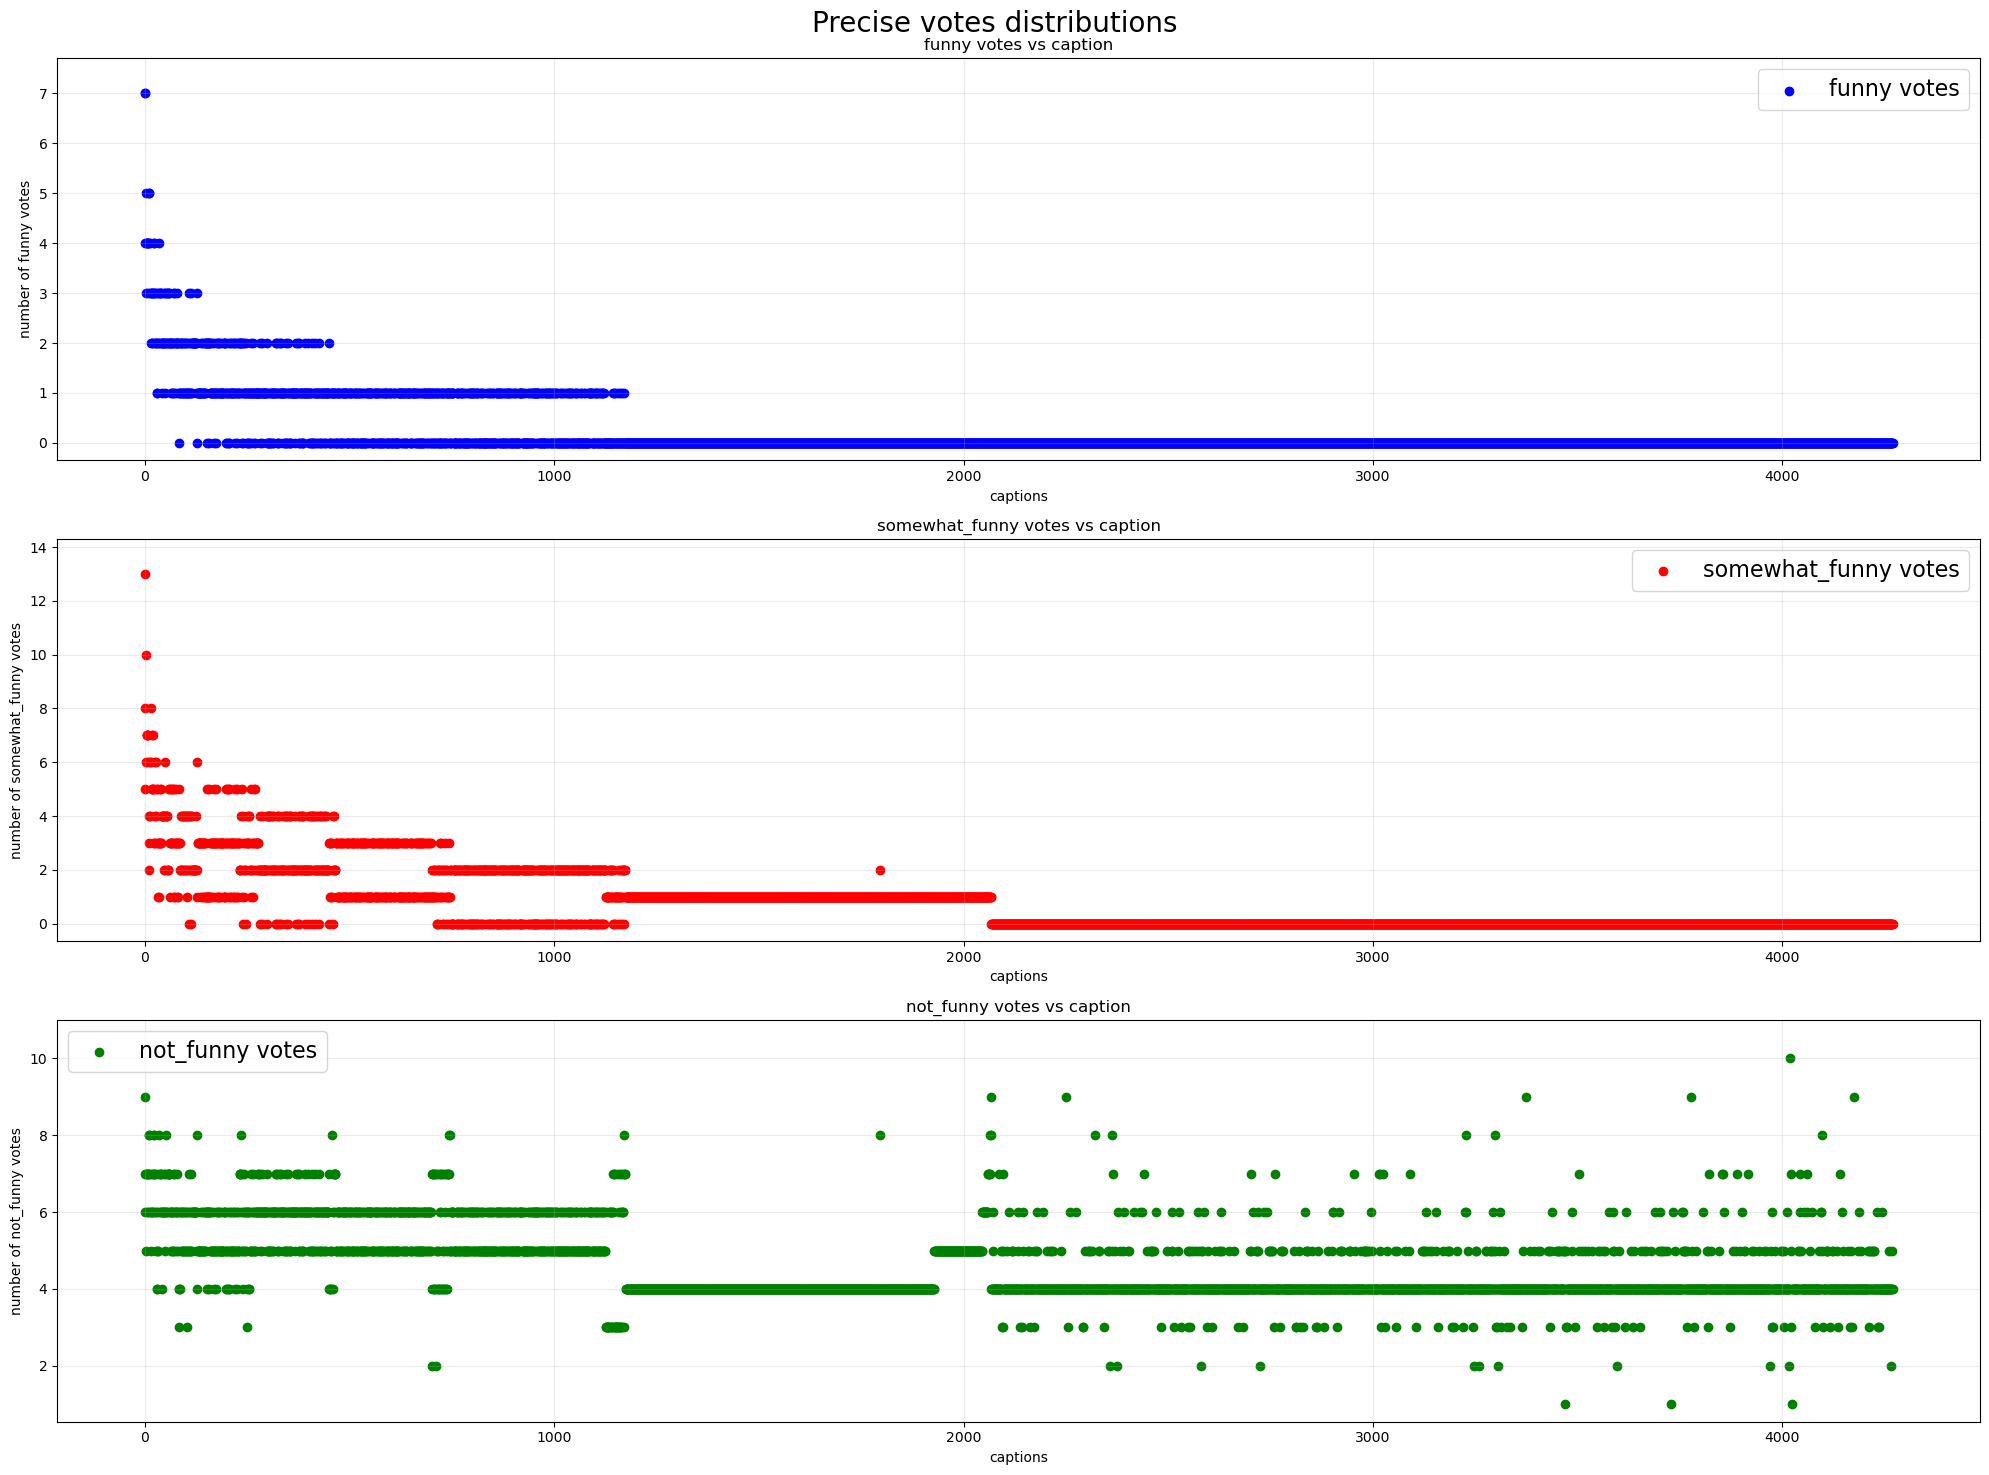

In [7]:
x = np.arange(len(contest_df))


plt.figure(figsize=(10,5))



# Cumulative scatter stacks (like bars, but with points)
plt.scatter(x, contest_df['funny'], color='blue', label='Funny votes', alpha=0.4)
plt.scatter(x, contest_df['somewhat_funny'] + contest_df['funny'], color='red', label='Somewhat funny votes', alpha=0.6)
plt.scatter(x, contest_df['not_funny'] + contest_df['somewhat_funny']+ contest_df['funny'], color='green', label='Not funny votes', alpha=0.8)


plt.title('Distribution of votes (cumulative)')
plt.xlabel('Captions')
plt.ylabel('Cumulative number of votes')
plt.tight_layout()
plt.legend()
plt.show()

def plot_divised_scatter_votes(df,figsize=(20, 15)):
    x = np.arange(len(df))
    plt.rcParams["figure.figsize"] = figsize  
    votes=['funny','somewhat_funny','not_funny']
    colors=['b','r','g']
    
    for i,vote in enumerate(votes):
        
        plt.subplot(3,1,i+1)
        plt.scatter(x,df[vote],label=f'{vote} votes',color=colors[i])
        maximum_value=max(df[vote])
        plt.ylim(top=1.1*maximum_value)
        if contest_df[vote].iloc[0]>100:
            plt.yscale("log")
        plt.title(f'{vote} votes vs caption')
        plt.xlabel('captions')
        plt.ylabel(f'number of {vote} votes')
        plt.grid(True, alpha=0.25)
        plt.legend(fontsize=16)
        
    plt.suptitle('Precise votes distributions',fontsize=20)
    plt.tight_layout()
    plt.show()

plot_divised_scatter_votes(contest_df)



### Divise into 3

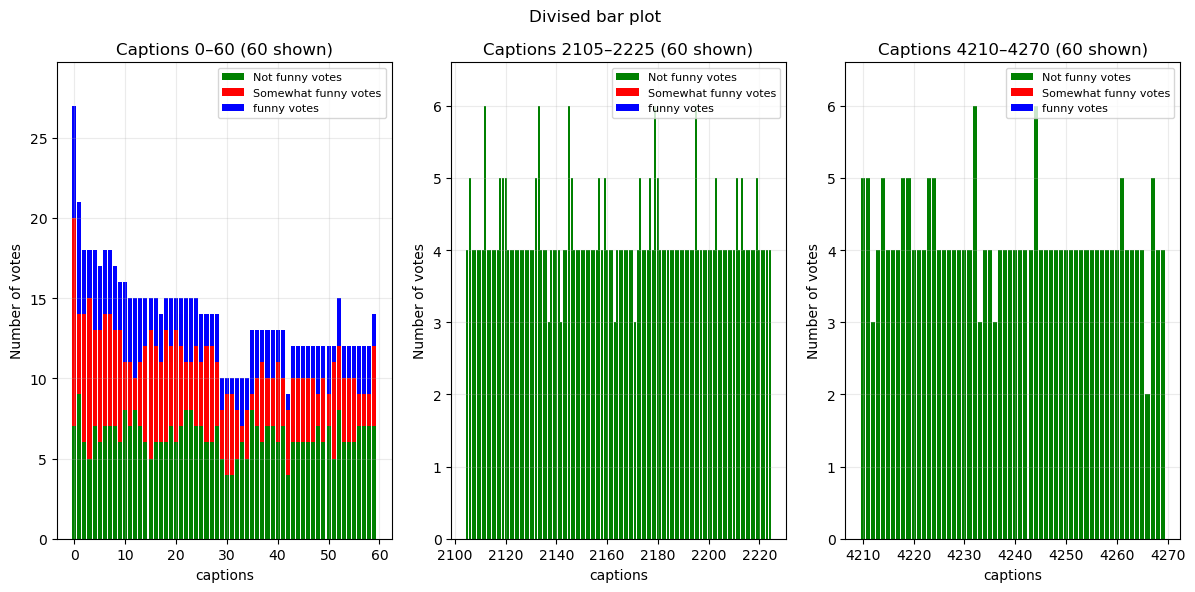

In [8]:
def plot_divised_histo_stacked(df,division=3,n_caption_per_div=20,figsize=(12,6)):
    plt.rcParams["figure.figsize"] = figsize  
    separation=floor(len(df)/(division-1))
    frame=[0,n_caption_per_div]
    
    for div in range(division):
        window=df.iloc[frame[0]:frame[1]]
        
        plt.subplot(1,division,div+1)
        plt.bar(window.index,window['not_funny'], color='green', label='Not funny votes')
        plt.bar(window.index,window['somewhat_funny'], bottom=window['not_funny'],color='red', label='Somewhat funny votes')
        plt.bar(window.index,window['funny'],bottom=(window['not_funny']+window['somewhat_funny']), color='blue', label='funny votes')
        
        maximum_value=max(window['not_funny']+window['somewhat_funny']+window['funny'])
        plt.ylim(top=1.1*maximum_value)
        
        plt.title(f'Captions {frame[0]}–{frame[1]} ({n_caption_per_div} shown)')
        plt.xlabel('captions')
        plt.ylabel('Number of votes')
        plt.grid(True, alpha=0.25)
        plt.legend(fontsize=8)
        
        start = frame[0] + separation - round(n_caption_per_div / 2)
        end = frame[1] + separation + round(n_caption_per_div / 2)
        start = max(0, start)
        end = min(len(df), end)
        frame = [start, end] 
    plt.suptitle('Divised bar plot')
    plt.tight_layout()
    plt.show()

plot_divised_histo_stacked(contest_df,n_caption_per_div=60)
        
        
    
    

Questions, at some point there are no more somewhat funny and fun votes ?

## Means visualisation

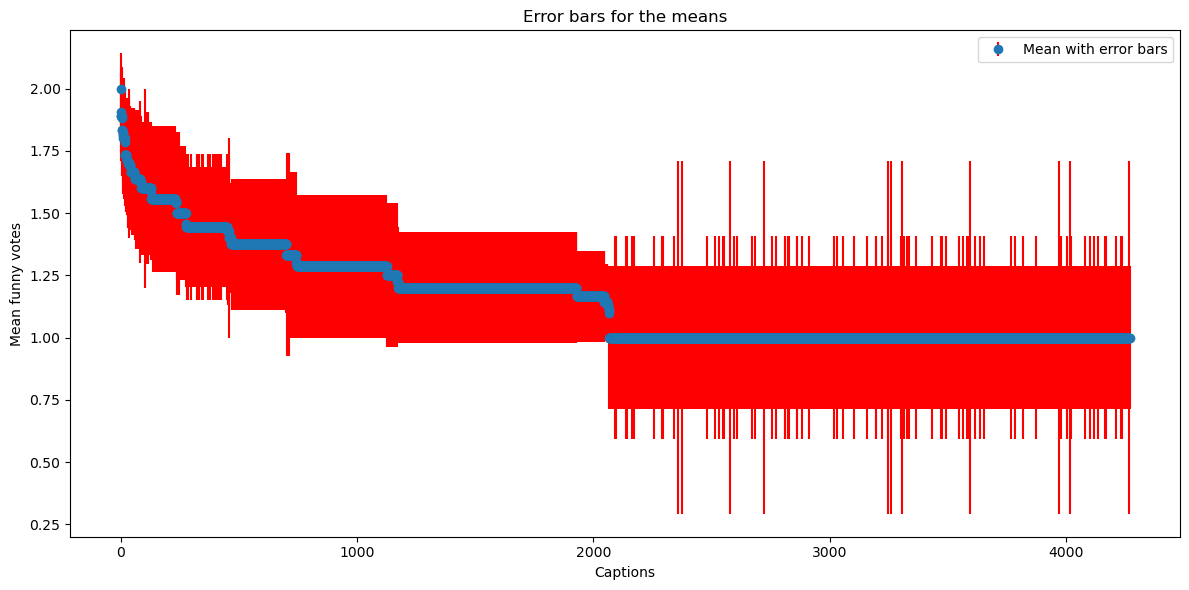

In [9]:
def scatter_error(df,figsize=(12,6)):
    plt.figure(figsize=figsize)
    plt.errorbar(df.index, df['mean'], yerr=df['precision'], fmt='o', ecolor='r', capthick=2,label='Mean with error bars')
    plt.title('Error bars for the means')
    plt.xlabel('Captions')
    plt.ylabel('Mean funny votes')
    plt.legend()
    plt.tight_layout()
    plt.show()

scatter_error(contest_df)





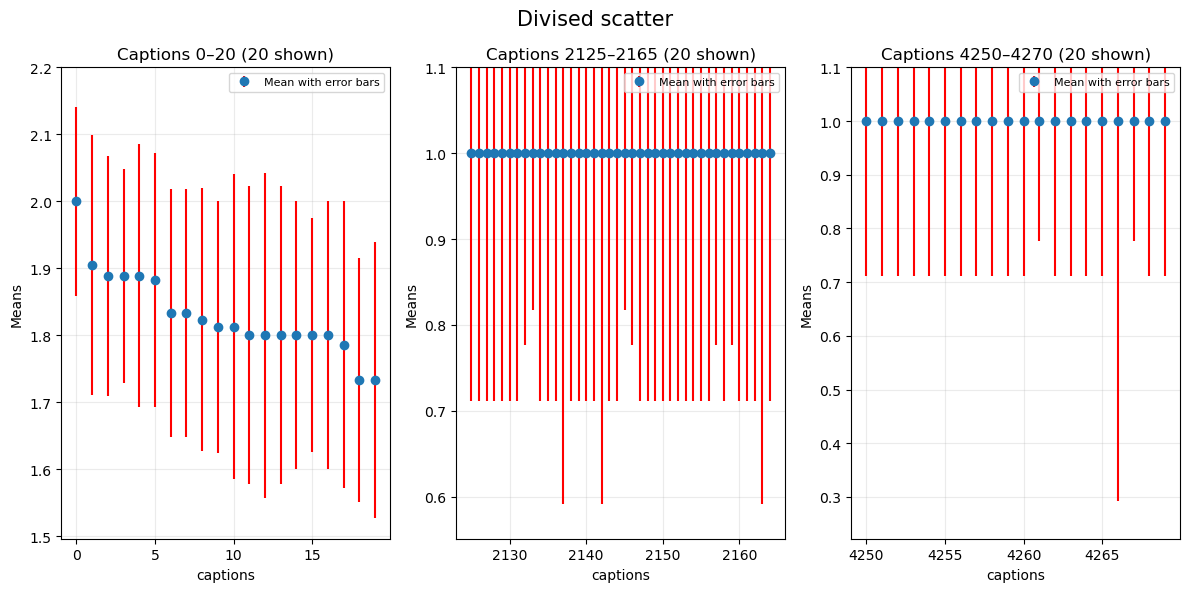

In [10]:
def plot_divised_scatter_error(df,division=3,n_caption_per_div=20,figsize=(12,6)):
    plt.rcParams["figure.figsize"] = figsize  
    separation=floor(len(df)/(division-1))
    frame=[0,n_caption_per_div]
    for div in range(division):
        window=df.iloc[frame[0]:frame[1]]
        
        plt.subplot(1,division,div+1)
        plt.errorbar(window.index, window['mean'], yerr=window['precision'], fmt='o', ecolor='r', capthick=2,label='Mean with error bars')
        
        maximum_value=max(window['mean'])
        plt.ylim(top=1.1*maximum_value)
        
        plt.title(f'Captions {frame[0]}–{frame[1]} ({n_caption_per_div} shown)')
        plt.xlabel('captions')
        plt.ylabel('Means')
        plt.grid(True, alpha=0.25)
        plt.legend(fontsize=8)
        
        start = frame[0] + separation - round(n_caption_per_div / 2)
        end = frame[1] + separation + round(n_caption_per_div / 2)
        start = max(0, start)
        end = min(len(df), end)
        frame = [start, end] 
    plt.suptitle('Divised scatter',fontsize=15)
    plt.tight_layout()
    plt.show()
    
plot_divised_scatter_error(contest_df)


The more we advance in the caption, n is smaller, precision larger, error bars larger, more constant is the mean

Heavy taled dist ?

Regrader le cours pour different graphs 

## Box plots Means

In [11]:
def box_plot(mean,ids,figsize=(12,6)):
    plt.figure(figsize=figsize)
    plt.boxplot(mean,orientation='horizontal',vert=False, patch_artist=True)
    plt.title('Boxplot of the means')
    plt.tight_layout()
    plt.show()
box_plot(contest_df['mean'])


TypeError: box_plot() missing 1 required positional argument: 'ids'

### Overall distribution of the means

/var/folders/mg/6kkx399d74d382844n7gl23r0000gn/T/ipykernel_8533/421213412.py:5: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



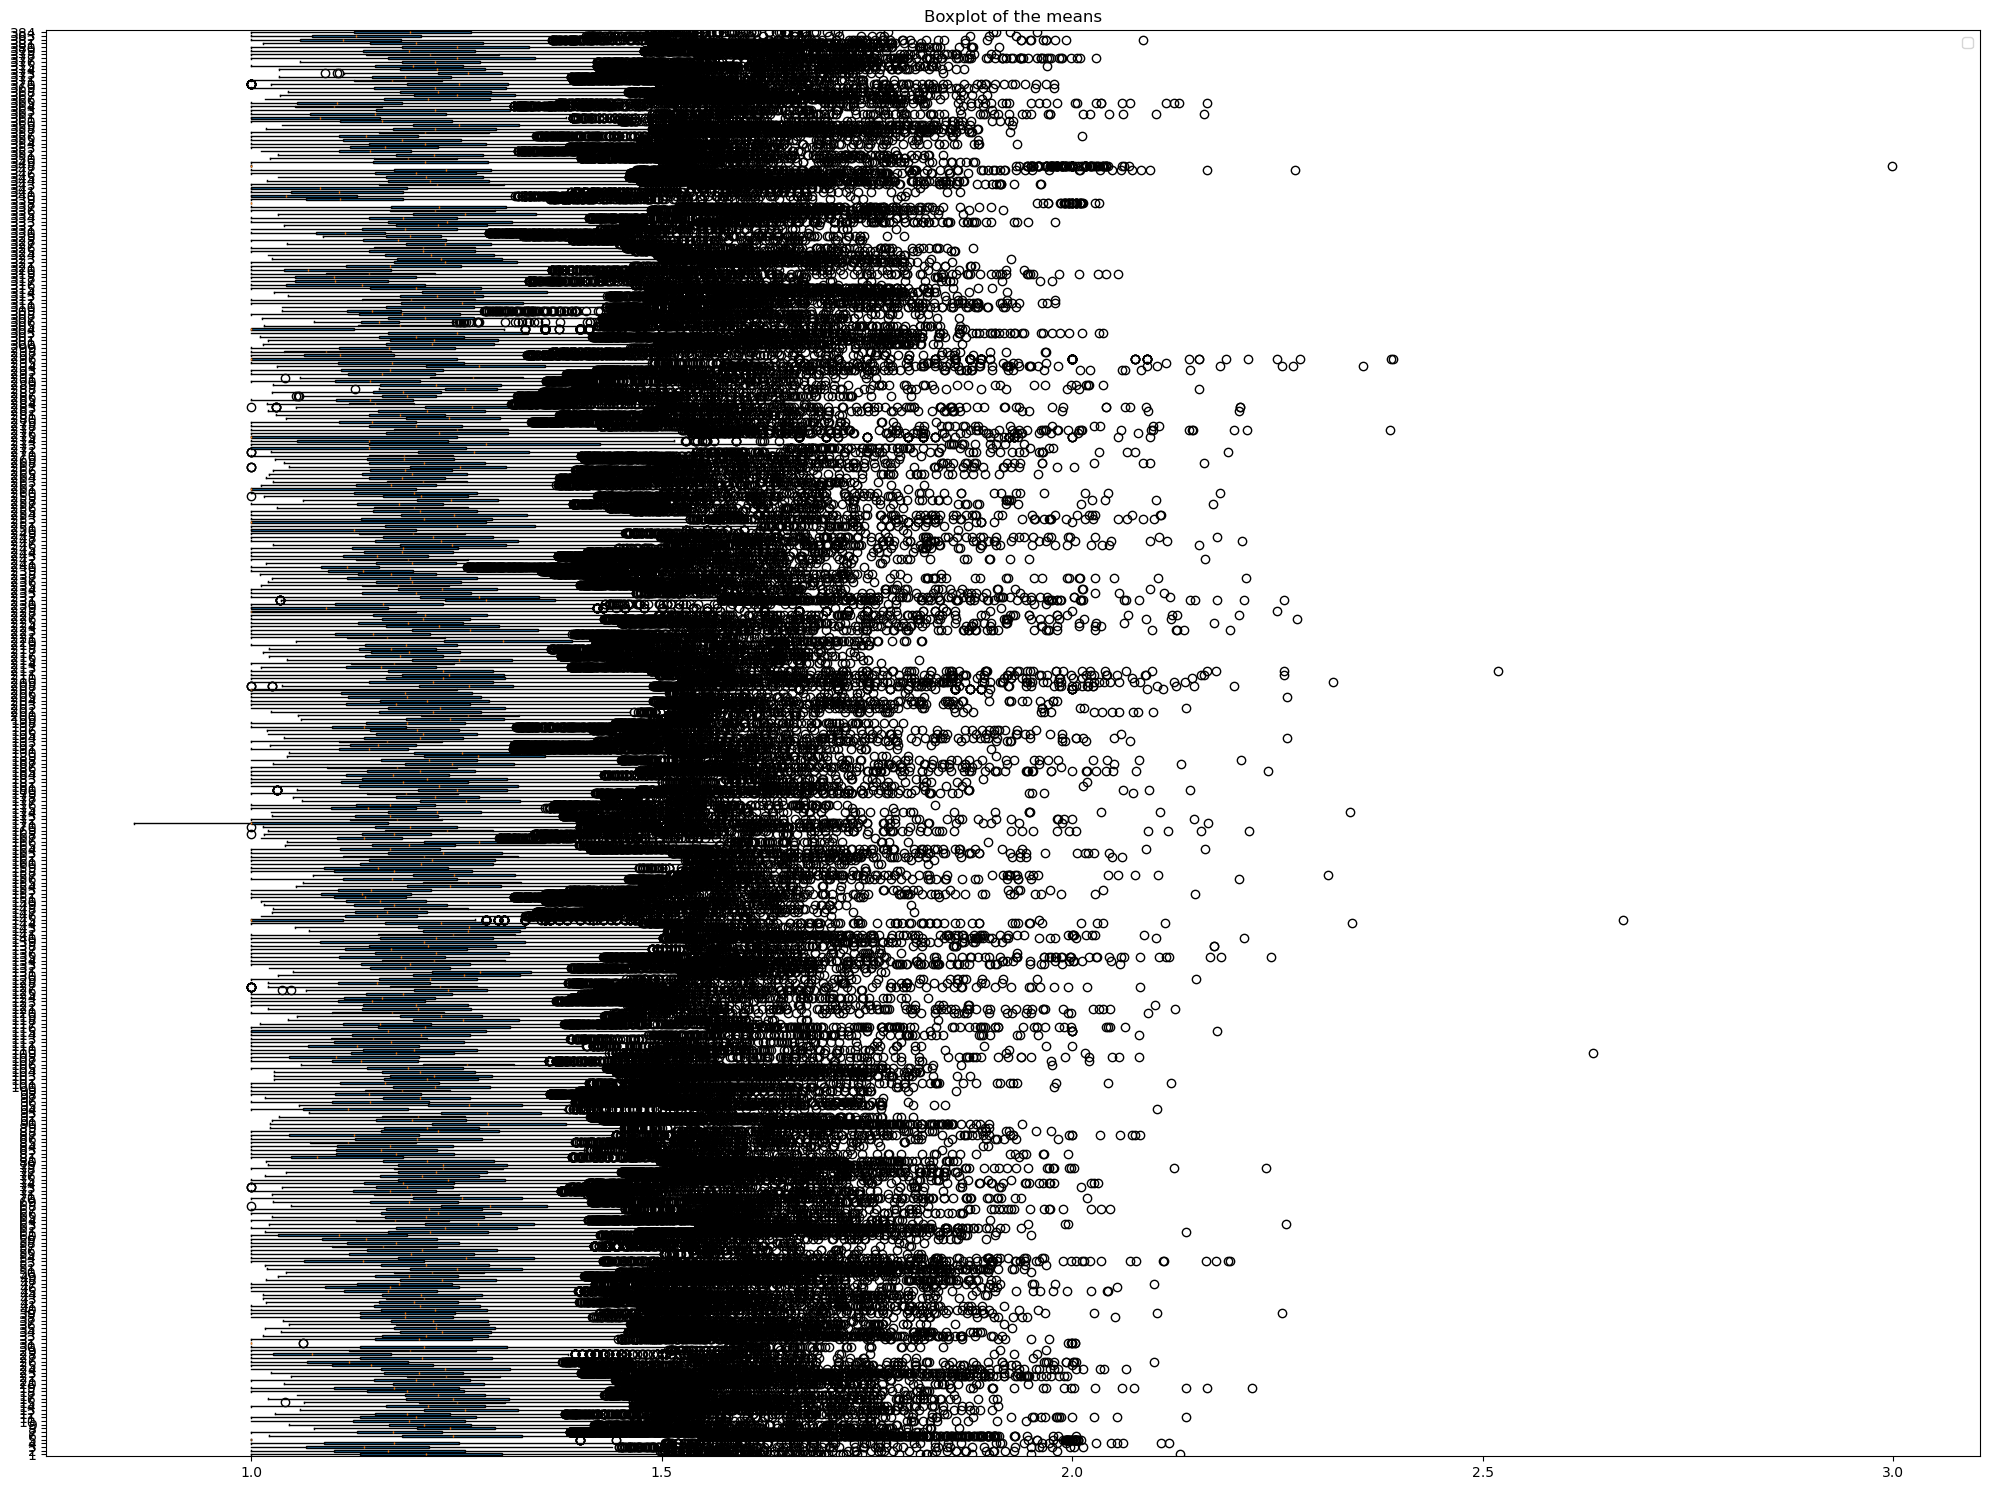

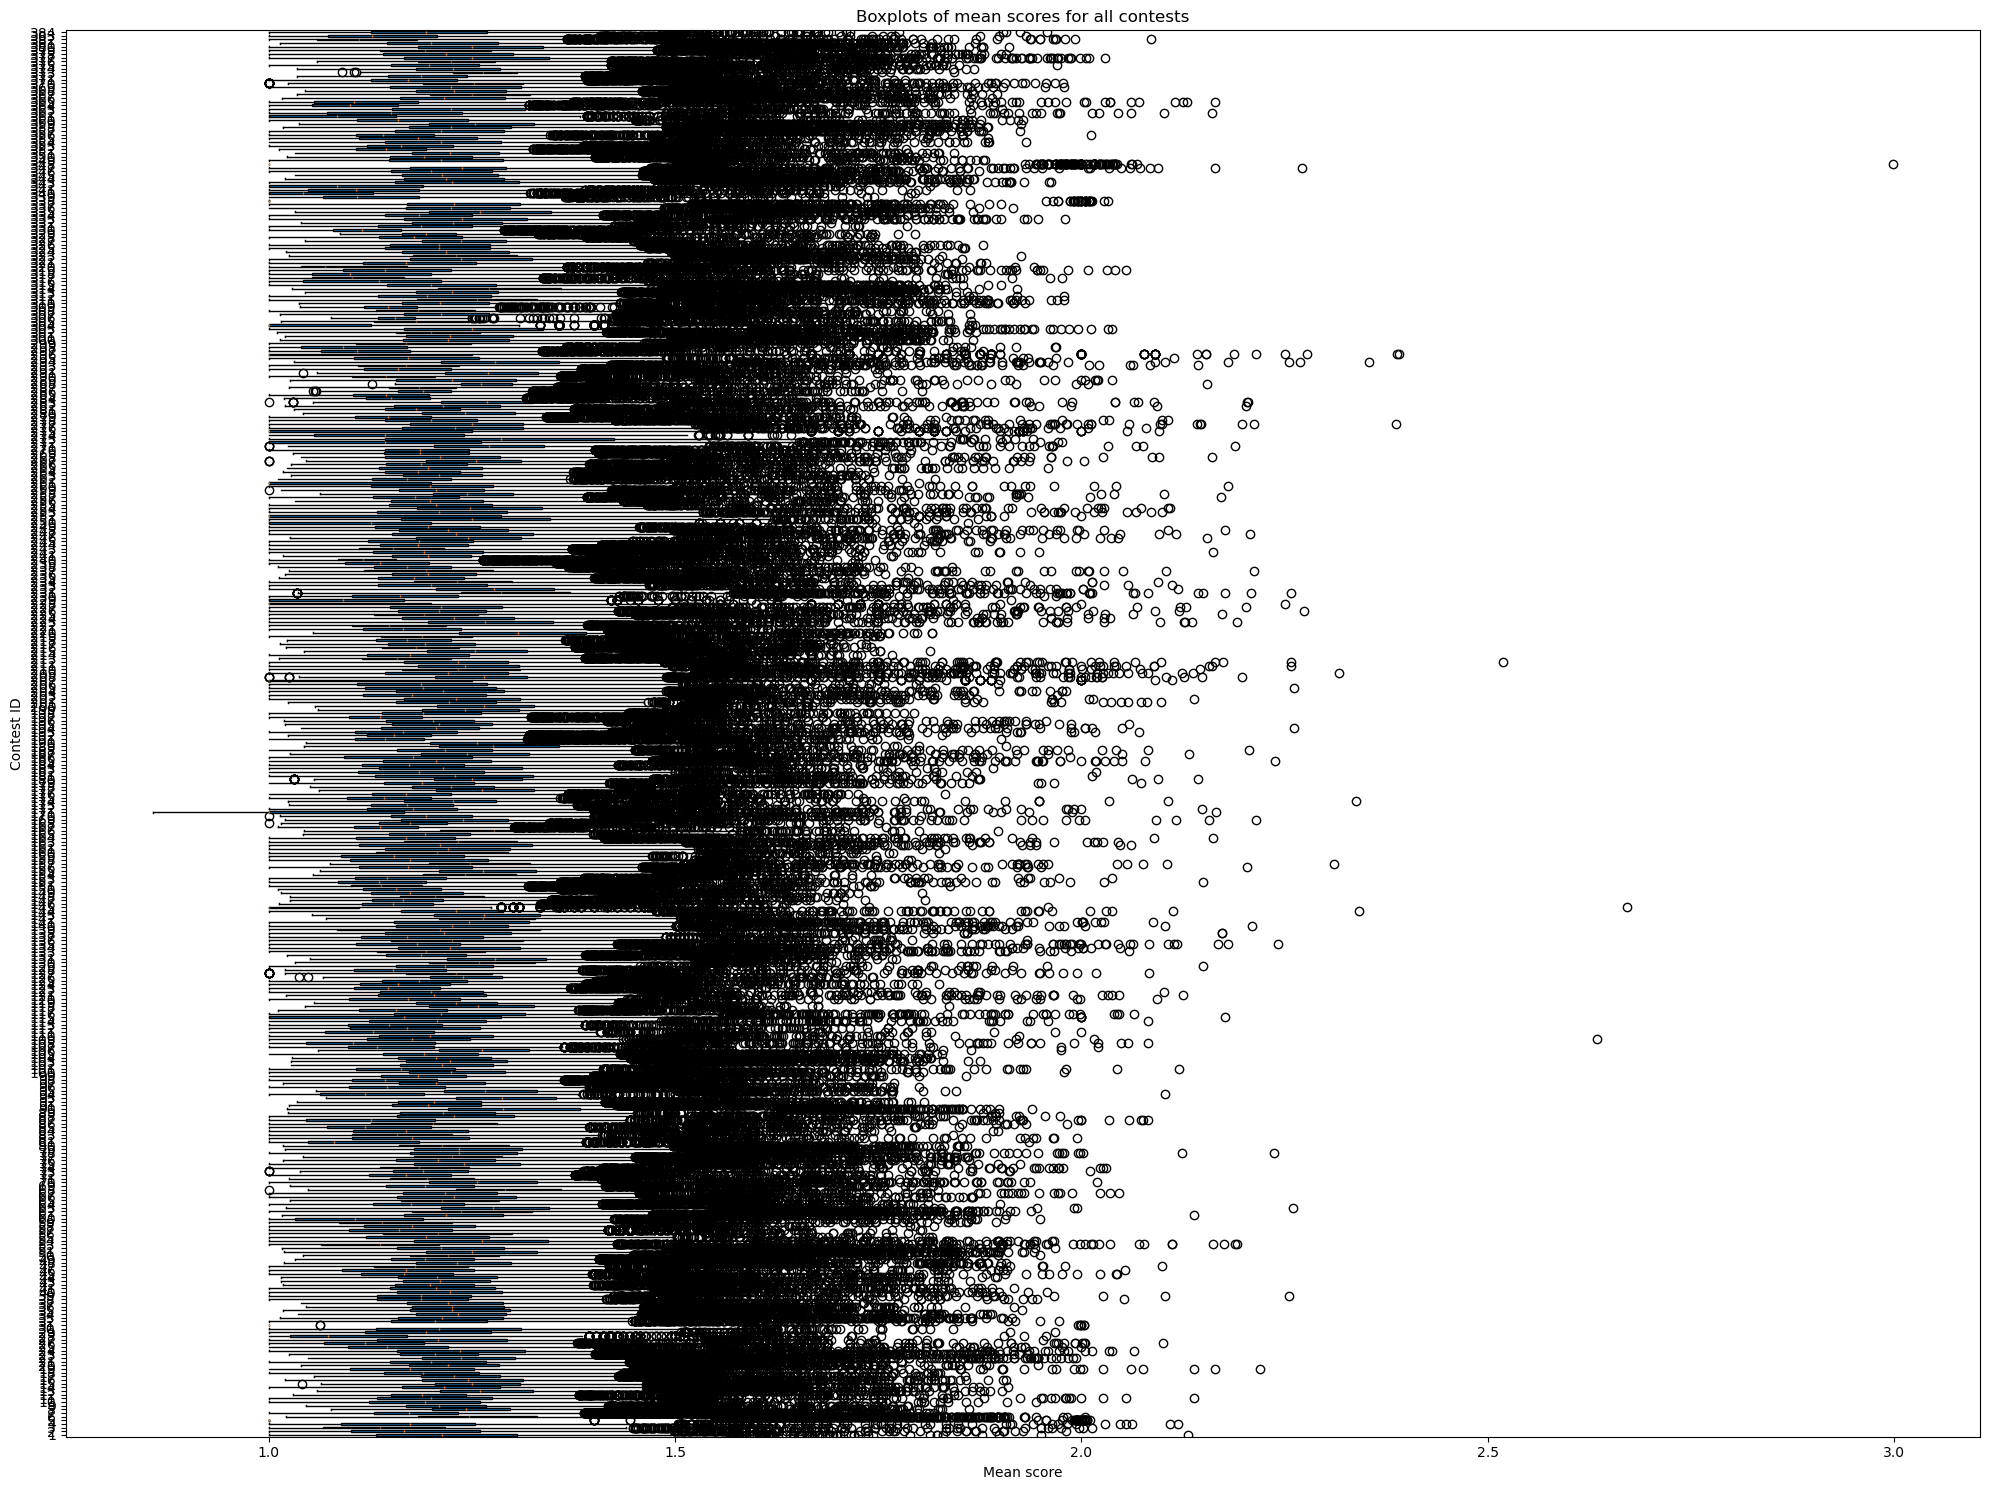

In [ ]:
def mean_ids_acquiring(root):
    all_means = []
    ids = []
    for file in os.listdir(root):
        if file.endswith(".csv"):
            contest_id = file.removesuffix(".csv")
            contest_df = pd.read_csv(os.path.join(root, file))
            all_means.append(contest_df['mean'].dropna())
            ids.append(f'{contest_id}')
    return all_means,ids

all_means,_=mean_ids_acquiring(root)
box_plot(all_means,figsize=(20, 15))

# Plot all at once
plt.figure(figsize=(20, 15))
plt.boxplot(all_means, vert=False, patch_artist=True)
plt.title('Boxplots of mean scores for all contests')
plt.xlabel('Mean score')
plt.ylabel('Contest ID')
plt.tight_layout()
plt.show()

## When does the funny votes and somewhat funny votes drop ?

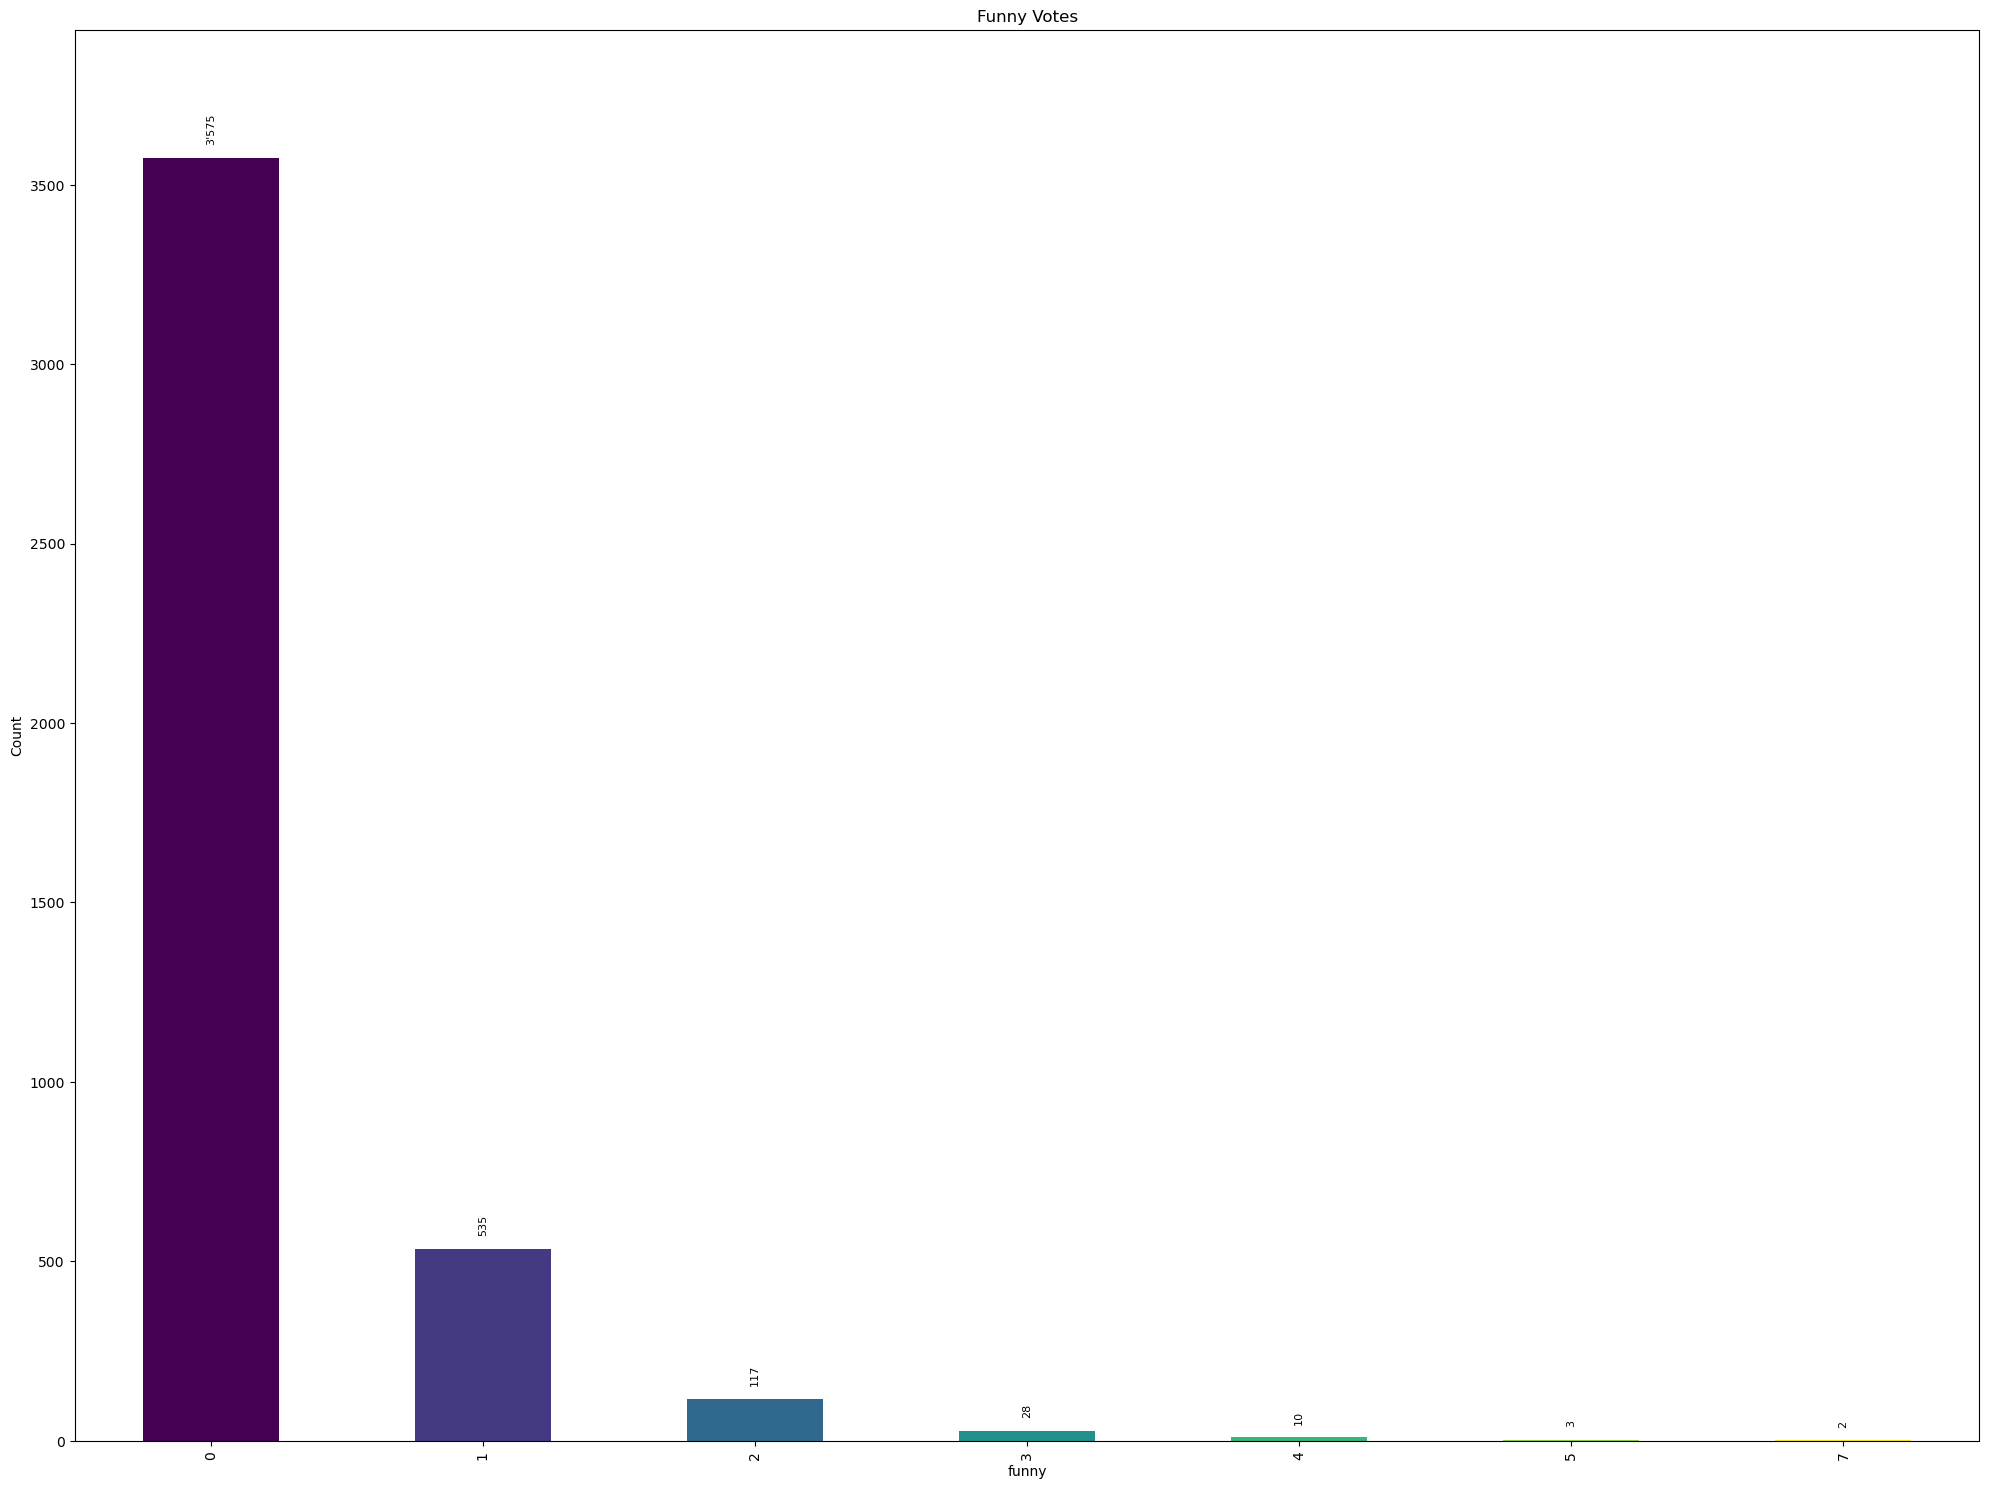

In [ ]:
# Example usage:
plot_df_histogram(contest_df,
                   class_col='funny',
                   top_n=None,
                   figsize=(20,15),
                   title='Funny Votes',
                   cmap='viridis',
                   log_scale=False)




In [ ]:
def plot_funny_dist(root):
    funny_distribution=pd.DataFrame({'contest_id':[0],'funny':[0]})
    for file in os.listdir(root):
        if file.endswith(".csv"):
            contest_id = file.removesuffix(".csv")
            contest_df = pd.read_csv(os.path.join(root, file))
            funny=0
            for funny_votes in contest_df['funny']:
                if funny_votes>0:
                    funny+=1
            temporary=pd.DataFrame({'contest_id':[int(contest_id)],'funny':[funny]})
            funny_distribution = pd.concat([funny_distribution, temporary], ignore_index=True)
            

    funny_distribution=funny_distribution.drop(index=0)
    funny_distribution=funny_distribution.sort_values('contest_id')
    fig = px.scatter(
        funny_distribution,
        x='contest_id',        # or 'contest_num' if numeric
        y='funny',
        hover_data=['contest_id', 'funny'],  # info shown on hover
        title='Number of funny captions per contest',
        labels={'contest_id': 'Contest', 'funny': 'Funny captions'},
    )

    fig.update_traces(marker=dict(size=8, color='blue', opacity=0.7))
    fig.update_layout(width=1200, height=600)
    fig.show()
    return funny_distribution

funny_dist=plot_funny_dist(root)


from pathlib import Path
import pandas as pd
import plotly.express as px

def plot_funny_dist(root):
    """
    Plot the number of captions with at least 1 'funny' vote per contest.
    
    Parameters
    ----------
    root : str or Path
        Directory containing CSV files named by contest_id.
        
    Returns
    -------
    funny_distribution : pandas.DataFrame
        DataFrame with columns ['contest_id', 'funny'].
    """
    root = Path(root)  # ensure root is a Path object
    funny_distribution = pd.DataFrame({'contest_id': [0], 'funny': [0]})

    for file in root.glob("*.csv"):  # Path-friendly iteration
        contest_id = file.stem  # removes '.csv' automatically
        contest_df = pd.read_csv(file)

        # Count captions with at least 1 funny vote
        funny = (contest_df['funny'] > 0).sum()

        temporary = pd.DataFrame({'contest_id': [int(contest_id)], 'funny': [funny]})
        funny_distribution = pd.concat([funny_distribution, temporary], ignore_index=True)

    # Remove dummy first row
    funny_distribution = funny_distribution.drop(index=0)
    funny_distribution = funny_distribution.sort_values('contest_id')

    # Plot
    fig = px.scatter(
        funny_distribution,
        x='contest_id',
        y='funny',
        hover_data=['contest_id', 'funny'],
        title='Number of funny captions per contest',
        labels={'contest_id': 'Contest', 'funny': 'Funny captions'},
    )
    fig.update_traces(marker=dict(size=8, color='blue', opacity=0.7))
    fig.update_layout(width=1200, height=600)
    fig.show()

    return funny_distribution



NameError: name 'root' is not defined